<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV6__Z%C3%A1klady_neuronov%C3%BDch_s%C3%AD%C5%A5%C3%AD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 6. -  Základy neuronových síťí
---
V tomto cvičení se konečně dostáváme k **neuronkám** - zaklínadlu 21. století. 🧙‍♂️ Cílem je si vytvořit svou **první jednoduchou neuronovou síť** a něco ji naučit - k tomu se nejlíp hodí klasifikační úloha. A aby to byla úloha hezká a názorná, bude to obrazová klasifikace, jak jinak. 🖼 K tomuto úkolu využijeme pomoci knihovny `TensorFlow`, která je v oblasti návrhu NN velmi dobře známá a používá se napříč celým světem. 🌍






## 🧩 Neuronová síť
Jeden z moderních prostředků umělé inteligence, volně inspirován biologií a neurologií mozku.

-  Jako předobraz využívá **biologické neurony**
- Má širokou oblast využití: *regrese, klasifikace, generování umělých dat, reinforcement learning atd.*
- Dělí se na vrstvy: vstupní, skryté (pracovní), výstupní

**Obecně:**
*Univerzální aproximátor funkce ( jakkoliv složité )*


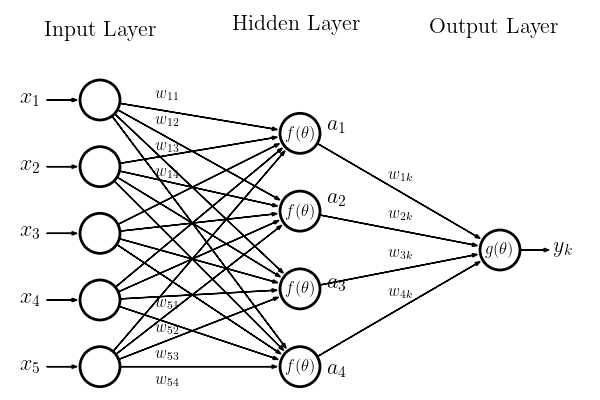

### 🤖 TensorFlow
TensorFlow je *open-source* knihovna pro strojové učení a hluboké učení vyvinutá společností *Google*. Umí možnosti **konstrukce a trénování širokého spektra modelů** umělé inteligence, včetně neuronových sítí, a je jednou z nejpopulárnějších knihoven v této oblasti.

Knihovna je známá svou efektivní manipulací s **tenzory** (matematické struktury podobné maticím) a nabízí širokou škálu nástrojů pro vývoj a experimentování s modely strojového učení.

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovny TensorFlow pro práci s neuronovými sítěmi
import tensorflow as tf

## 📃 ČÁST 1: Příprava dat: CIFAR-10
---
Jak už bylo řešeno, použijeme obrazový dataset určený pro klasifikaci - **CIFAR-10** (CIFAR stojí za "*Canadian Institute for Advanced Research*"). Jedná se balík rlzných obrázků z 10 tříd (pes, auto, kočka..)  a hodí se pro experimenty s klasifikačnímy modely.

### Popis datasetu:
*CIFAR-10 je jeden z populárních datasetů používaných v oblasti počítačového vidění a strojového učení. Tento dataset byl vytvořen pro účely trénování a testování algoritmů pro klasifikaci obrázků. Trénovací množina obsahuje 50 000 **barevných obrázků o rozměrech 32x32 pixelů**, rozdělených **do 10 tříd** (5 000 obrázků na třídu).
Testovací množina obsahuje 10 000 obrázků pro vyhodnocení výkonu modelu.*

**Sloupce:**
- Images: bitmapa obrázku 32x32 v RGB formátu (3 kanály / pixel)
- Labels: numerické vyjádření třídy obrázku - třídy lze namapovat na názvy

**Třídy:**
- 0: Letadlo
- 1: Automobil
- 2: Pták
- 3: Kočka
- 4: Jelen
- 5: Pes
- 6: Žába
- 7: Kůň
- 8: Loď
- 9: Nákladní auto

**Cíl:**
CIFAR-10 je často využíván pro vyhodnocování a porovnávání výkonu různých modelů v oblasti klasifikace obrazů.

In [ ]:
# Import CIFAR-10 datasetu
import tensorflow as tf
cifar10 = tf.keras.datasets.cifar10

# Načtení CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
# Definice funkce která převádí pole na obrázek
from PIL import Image

def arr_to_bmp(array_data, mode="RGB", size=(64,64)):
  img = Image.fromarray(array_data, mode).resize(size)
  return img

### 🔭 Explorační analýza
*Není třeba provádět důkladnou analýzu, jedná se o čistý dataset.*

In [ ]:
# Zkontrolujeme shape a počet dat
train_images.shape, test_images.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

In [ ]:
train_images.ndim, test_images.ndim

(4, 4)

In [ ]:
train_labels.shape, test_labels.shape

((50000, 1), (10000, 1))

✍ *Vsuvka:* Všimnite si tvaru vstupních dat - `train_images`. Mají tvar `(50000, 32, 32, 3)`, což značí 50000 obrázků, 32 pixelů / řádek, 32 pixelů / sloupec a 3 kanýly na pixel (RGB).

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], dtype=uint8)
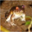

In [ ]:
# Podíváme se na čistý náhlad vzorků dat
train_images[0]

/tmp/ipython-input-2284591411.py:5: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(array_data, mode).resize(size)


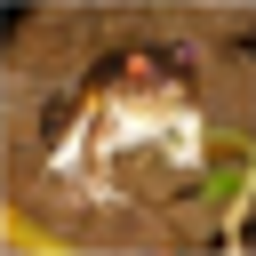

In [ ]:
arr_to_bmp(train_images[0], size=(256,256))

In [ ]:
train_labels[0]

array([6], dtype=uint8)

### 🧠 ÚKOL 1:
Dopište následující funkci, která bude překládat číselný index trřídy (0-9) na název třídy (pes, kočka, auto...).





In [ ]:
# Slovník pro překlad - mapa, píše se ve tvaru key:value
cifar10_class_dict = ???

def index_to_class(index:int, map:dict):
  ???

In [ ]:
#  Otestovat index_to_class
index_to_class(0, cifar10_class_dict)

'Letadlo'

In [ ]:
# Náhled dat - vizualizace (prvních 10)
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title(f'{index_to_class(train_labels[i][-1], cifar10_class_dict)}')
    plt.axis('off')

# Zarovná layout
plt.tight_layout()

## ✂️ Rozdělení a úprava dat
Jako vstupy `X` použijeme bitmapy číslic (neboli `train_images`) a jako výstupy `y` použijeme textové prezentace číslic, neboli `train_labels`.

**Protože je dataset již předrozdělen na vstupy a výstupy, a dokonce i na trénovací a testovací data**, není třeba už jej jinak dělit, pouze je uložíme do proměnných `X_train`, `X_test`, `y_train` a `y_test`.

In [ ]:
X_train = train_images
X_test = test_images

y_train = train_labels
y_test = test_labels

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3), (50000, 1), (10000, 1))

### Úprava dimenze
Data jsou 3 dimenzionální - *řádky*, *sloupce* a *kanály*. Neuronovou síť lze učit buď v tomto tvaru, nebo tvar upravit na nějaký méně dimenzionální - provést takzvané "zplacatění" dat - `flatten`. Tím sločíme řádky, sloupce a kanály do jedné dimenze.

In [ ]:
X_train = X_train.reshape(-1, 32*32*3)
X_test = X_test.reshape(-1, 32*32*3)

X_train.shape, X_test.shape

((50000, 3072), (10000, 3072))

✍ *Vsuvka:* **-1** zde znamená, že tato dimenze bude mít stejný tvar jako původní dimenze na kterou je aplikován `reshape`.

In [ ]:
X_train[0]

array([ 59,  62,  63, ..., 123,  92,  72], dtype=uint8)

### Normalizace dat
Aby se model efektivněji trénoval a srovnali se případné odchylky mezi daty, je dobrou praxí jej **normalizovat**. To znamená, že všechny hodnoty "*naskejlujeme*" na interval mezi `<0,1>` nebo `<-1,1>`. K tomuto využijeme funkci `min_max_scaler` která to udělá za nás nebo to uděláme ručně, operace kterou scaler provádí je následující: `X_norm = X - min(X) / max(X) - min(X)`.

In [ ]:
# Normalizace
X_train, X_test = X_train/255.0, X_test/255.0

In [ ]:
X_train[0]

array([0.23137255, 0.24313725, 0.24705882, ..., 0.48235294, 0.36078431,
       0.28235294])

✍ *Vsuvka:* Zde je min 0, tedy ho lze vynechat a prostě vydělit dataset maximem - 255. ➗

### Zkrácení datasetu
V případě neuronových síťí **není** obvykle chtěné krátit dataset ❗ Chceme pokud možno co nejvíce trénovacích a testovacích dat.



# ⭐ Vytvoření modelů
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

### 🧭 **Sekvenční** X **Manuální**
TensorFlow umožňuje zápis neuronových síťí buď sekvenční formou, nebo manuláně skládat vrstvu za vrstvou. Ukážeme si oba tyto přístupy.

#### Sekvenční přístup

In [ ]:
# Definice modelu
model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=128, activation='relu', input_shape=(32*32*3,)),
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=10, activation='softmax')
])
model.summary()

Model: "sequential_14"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_49 (Dense)            (None, 128)               393344    
                                                                 
 dense_50 (Dense)            (None, 64)                8256      
                                                                 
 dense_51 (Dense)            (None, 10)                650       
                                                                 
Total params: 402250 (1.53 MB)
Trainable params: 402250 (1.53 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


#### Manuální přístup

In [ ]:
X_train.shape

(50000, 3072)

In [ ]:
 # Vytvoření modelu

 # Vstupní vrstva
input_layer = tf.keras.layers.Input(shape=((32*32*3,)))
 # Skryté vrstvy
x = tf.keras.layers.Dense(units=128, activation='relu')(input_layer)
x = tf.keras.layers.Dense(units=64, activation='relu')(x)
 # Výstupní vrstva
output_layer = tf.keras.layers.Dense(units=10, activation='softmax')(x)

# Sestavení modelu
model = tf.keras.Model(input_layer, output_layer)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

**Rozbor modelu:**
- `Sequential`: obalí vrstvy a automaticky z nich vytvoří sekvenci -> `model`
- `Dense`: "hustě propojená vrstva", základní klasická vrstva neuronové sítě, všechny neuronony jsou propojené na všechny [(doc)](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense)
  - *units* : počet neuronů v této vrstvě
  - *activation*: typ použité aktivační funkce
  - *input_shape*: vstupní tvar dat, značí že tato vrstva je vstupní
  - *softmax*: dává se do výstupní vrstvy, transformuje výstup na distribuci pravděpodobnosti jednotlivých tříd, v našem případě jde o 10 tříd.

- `summary` : vypíše strukturu modelu

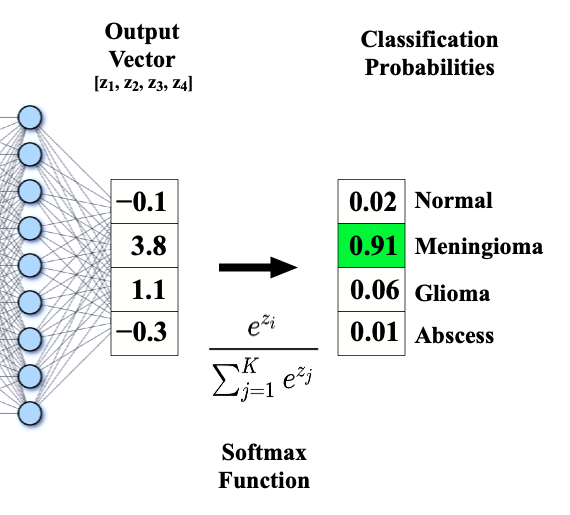

### 💪 Kompilace a trénování modelu

In [ ]:
# Kompilace modelu
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])

In [ ]:
# Kompilace modelu - pomocí textových aliasů
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

✍ *Vsuvka:* Místo konkterétních tříd můžete používat textové aliasy. 😎

**Rozbor kompilace modelu:**
- *optimizer*: optimalizuje váhy modelu v závislosti na ztrátě
- *loss*: funkce která počítá ztrátu
  - *SparseCategoricalCrossentropy*: značí že očekáváme klasifikaci dat do kategorií, kde každá kategorie bude označena celým číslem, například 5.
- *metrics*: metriky které chceme na modelu dodatečně měřit, může jít výkon a nebo o přesnost, chybovost atd...

In [ ]:
# Trénování modelu
epochs = 10
history = model.fit(X_train, y_train, epochs=epochs, batch_size=64)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.2712 - loss: 2.0223
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.3841 - loss: 1.7247
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.4096 - loss: 1.6469
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4385 - loss: 1.5814
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4441 - loss: 1.5591
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.4544 - loss: 1.5303
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4620 - loss: 1.5058
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4674 - loss: 1.4861
Epoch 9/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4794 - loss: 1.4612
Epoch 10/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.4836 - loss: 1.4439


✍ *Vsuvka:* Trénování modelu zabere nějaký čas, je třeba pár min počkat ⏰

**Rozbor trénování modelu:**
- `history`: zde se ukládá historie trénování v jednotlivých epochách
- *epochs*: počet epoch pro treénování modelu (víc nemusí být lepší)
- *batch_size*: velikost dávky, kolik dat (počet záznamů/trénovacích jednotek/obrázků) má model projít než upraví váhy - *jak dlouhá má být jedna epocha*.

### ✅ Testování modelu
Model otestujeme klasickou funkcí `score` nebo externí metrikou.

In [ ]:
# Vyhodnocení přesnosti modelu
loss, sparse_categorical_accuracy = model.evaluate(X_test, y_test)
loss, sparse_categorical_accuracy

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4659 - loss: 1.4986


(1.5024060010910034, 0.4641999900341034)

### 📈 Metriky
Pro lepší přehled o průběhu trénování modelu si vykreslíme metriky.

In [ ]:
def show_history(history, ignore_val = True):
    plt.figure()
    for key in history.history.keys():
      if key.find("val") != -1 and ignore_val:
        continue
      plt.plot(history.epoch, history.history[key], label=key)
    plt.legend()
    plt.tight_layout()

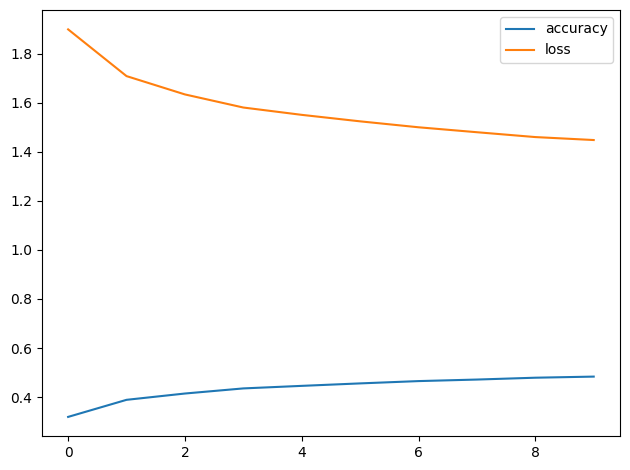

In [ ]:
show_history(history)

✍ *Vsuvka:* Tento model je velmi špatný 😞 Jak vidíte, přesnost je maximálně 50%, a ztráta je stále hodně vysoká. Cílem trénování je především snižovat ztrátu! ↘ **Dokud se snižuje ztráta, znamená to že model se stále zlepšuje!**

### 👁️ Predikce:

In [ ]:
# Použiji testovací data které model nezná a predikuji 16 záznamů
y_pred = model.predict(X_test[:16])

#Kontrola tvaru
y_pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


(16, 10)

In [ ]:
# Náhled jednoho záznamu
y_pred[0]

array([0.2543917 , 0.10007861, 0.10235564, 0.09919894, 0.03959614,
       0.05616177, 0.08285214, 0.0008559 , 0.252634  , 0.01187509],
      dtype=float32)

✍ *Vsuvka:* Jak vydíme, **predikce nevypadá úplně tak jak bychom chtěli** - místo čísla classy jsme obdrželi **distribuci pravděpodobnosti** pro jednotlivé třídy poskytnuté funkcí `softmax`.

In [ ]:
y_test[0]

array([3], dtype=uint8)

In [ ]:
index_to_class(3, cifar10_class_dict)

'Kočka'

In [ ]:
index_to_class(6, cifar10_class_dict)

'Žába'

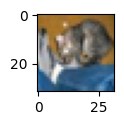

In [ ]:
plt.figure(figsize=(1,1))
plt.imshow(X_test[0].reshape(32,32,3))

### 🧠 ÚKOL 2:

Napiš funkci pro převod mezi distribucí pravděpodobností a konkterétní třídou

In [ ]:
# Funkce pro převod mezi distribucí pravděpodobnosti a číslem třídy
# Probs: predikované distribuce pravděpodobností
def probs_to_classes(probs):
  ???

In [ ]:
# Konvertuj
y_pred_classes = probs_to_classes(y_pred)
y_pred_classes

array([0, 8, 0, 8, 4, 6, 1, 6, 4, 1, 8, 9, 4, 7, 1, 8])

In [ ]:
y_test[:16]

array([[3],
       [8],
       [8],
       [0],
       [6],
       [6],
       [1],
       [6],
       [3],
       [1],
       [0],
       [9],
       [5],
       [7],
       [9],
       [8]], dtype=uint8)

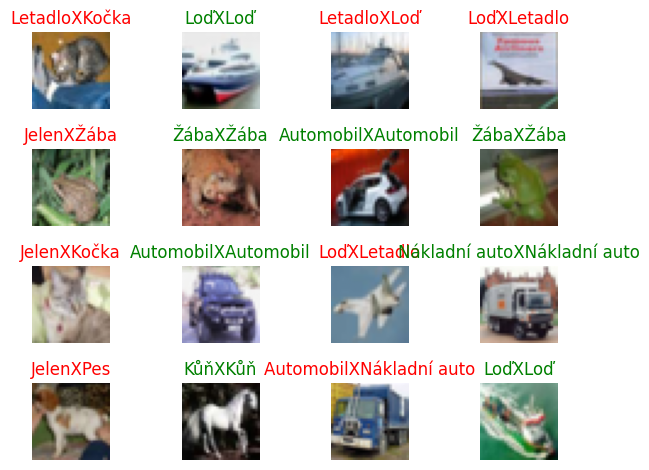

In [ ]:
y_pred_classes = probs_to_classes(y_pred)
y_test_classes = y_test.reshape(-1)

for i in range(16):
    plt.subplot(4, 4, i+1)
    # Musím provést reversní reshape dat zpět na rozměr 32x32x3
    plt.imshow(X_test[i].reshape(32,32,3))
    pred_val = index_to_class(y_pred_classes[i], cifar10_class_dict)
    true_val = index_to_class(y_test_classes[i], cifar10_class_dict)
    # c = "b" if y_pred[i] == y_test[i] else "r" - inline ternární operátor který přepíná barvu mezi g (green) a r (red)
    plt.title(f'{pred_val}X{true_val}', c = "g" if y_pred_classes[i] == y_test[i] else "r")
    plt.axis('off')

# Zarovná layout
plt.tight_layout()

### 🧠 ÚKOL 3:
Vytvořte **další modely (alespoň jeden)**, buď sekvenční nebo manulální metodou. Zkuste nastavit **různé parametry sítě**, velikost vrstev, počet epoch a otestujte je. Ten s nejlepším skore použijte pro další úkol. Zkuste dosáhnout skore alespoň **70 %**! 📈

Pozor na názvy proměnných do kterých modely ukládáte, model se stejným názvem proměnné přepíše starý model ❗





In [ ]:
#řešení úkolu č. 2:

In [ ]:
 # Vytvoření modelu

 # Vstupní vrstva
input_layer = ...
 # Skryté vrstvy
x = ...
...
 # Výstupní vrstva
output_layer = ...

# Sestavení modelu
model = tf.keras.Model(input_layer, output_layer)
model.summary()

In [ ]:
# Kompilace modelu
# Použijte optimizér ADAM, ztrátu jako Sparse Categorical Crossentropy, metriku accuracy nebo F1
model.???

In [ ]:
# Trénování modelu, nastav počet epoch podle sebe
epochs = ?
history = model.???

In [ ]:
# Zobraz historii z trénování pomocí fznkce show_history(history)
???

In [ ]:
# Otestuj model
model.???

In [ ]:
# Udělej ukázku prvních 16 předpovězených a skutečných obrázků
???

### 🧠 ÚKOL 4:
Přidejte před výstupní vstrvu vrstvu `Dropout` s parametrem 0.1 až 0.5. Sledujte co se stane.





In [ ]:
#řešení úkolu č. 3: